<a href="https://colab.research.google.com/github/kduran-stack/climate_collection_kd/blob/draft-plots1/DHW_Draft.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
url= "https://coastwatch.pfeg.noaa.gov/erddap/griddap/NOAA_DHW.csv?CRW_DHW%5B(1985-03-25T12:00:00Z):1:(last)%5D%5B(26.00):1:(26.25)%5D%5B(-80.125):1:(-80.00)%5D,CRW_SST%5B(1985-03-25T12:00:00Z):1:(last)%5D%5B(26.00):1:(26.25)%5D%5B(-80.125):1:(-80.00)%5Durl"

In [3]:
!pip install xarray netcdf4 pydap cartopy
import urllib.request
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np

In [4]:
# target_dates = [
#     "1986-10-29T12:00:00Z",
#     "1996-10-29T12:00:00Z",
#     "2006-10-29T12:00:00Z",
#     "2016-10-29T12:00:00Z",
#     "2026-10-29T12:00:00Z",
# ]

# # Download each timestamp's 3x3 degree subset directly as a local NetCDF file
# datasets = []
# for dt in target_dates:
#     query_url = (
#         f"https://coastwatch.pfeg.noaa.gov/erddap/griddap/NOAA_DHW.nc?"
#         f"CRW_DHW[({dt})][(27.5):1:(24.5)][(-81.5):1:(-78.5)]"
#     )
#     local_file = f"dhw_{dt[:10]}.nc"
#     urllib.request.urlretrieve(query_url, local_file)
#     datasets.append(xr.open_dataset(local_file))

# # Combine the 5 slices along the time dimension
# regional_dhw = xr.concat(datasets, dim="time")["CRW_DHW"]


HTTPError: HTTP Error 503: 

In [5]:
import os
import time
import urllib.request
from urllib.error import HTTPError
import xarray as xr

target_dates = [
    "1986-10-29T12:00:00Z",
    "1996-10-29T12:00:00Z",
    "2006-10-29T12:00:00Z",
    "2016-10-29T12:00:00Z",
    "2026-10-29T12:00:00Z",
]

datasets = []
for dt in target_dates:
    local_file = f"dhw_{dt[:10]}.nc"
    query_url = (
        f"https://coastwatch.pfeg.noaa.gov/erddap/griddap/NOAA_DHW.nc?"
        f"CRW_DHW[({dt})][(27.5):1:(24.5)][(-81.5):1:(-78.5)]"
    )

    #download if the file isn't already saved locally
    if not os.path.exists(local_file):
        for attempt in range(4):
            try:
                urllib.request.urlretrieve(query_url, local_file)
                time.sleep(2)  # Be polite to NOAA's server between requests
                break
            except HTTPError as e:
                if e.code == 503 and attempt < 3:
                    print(f"Server busy (503) for {dt[:10]}, retrying in 5s...")
                    time.sleep(5)
                else:
                    raise

    datasets.append(xr.open_dataset(local_file))

# combining slices
regional_dhw = xr.concat(datasets, dim="time")["CRW_DHW"]
print("All 5 slices loaded successfully!")

All 5 slices loaded successfully!


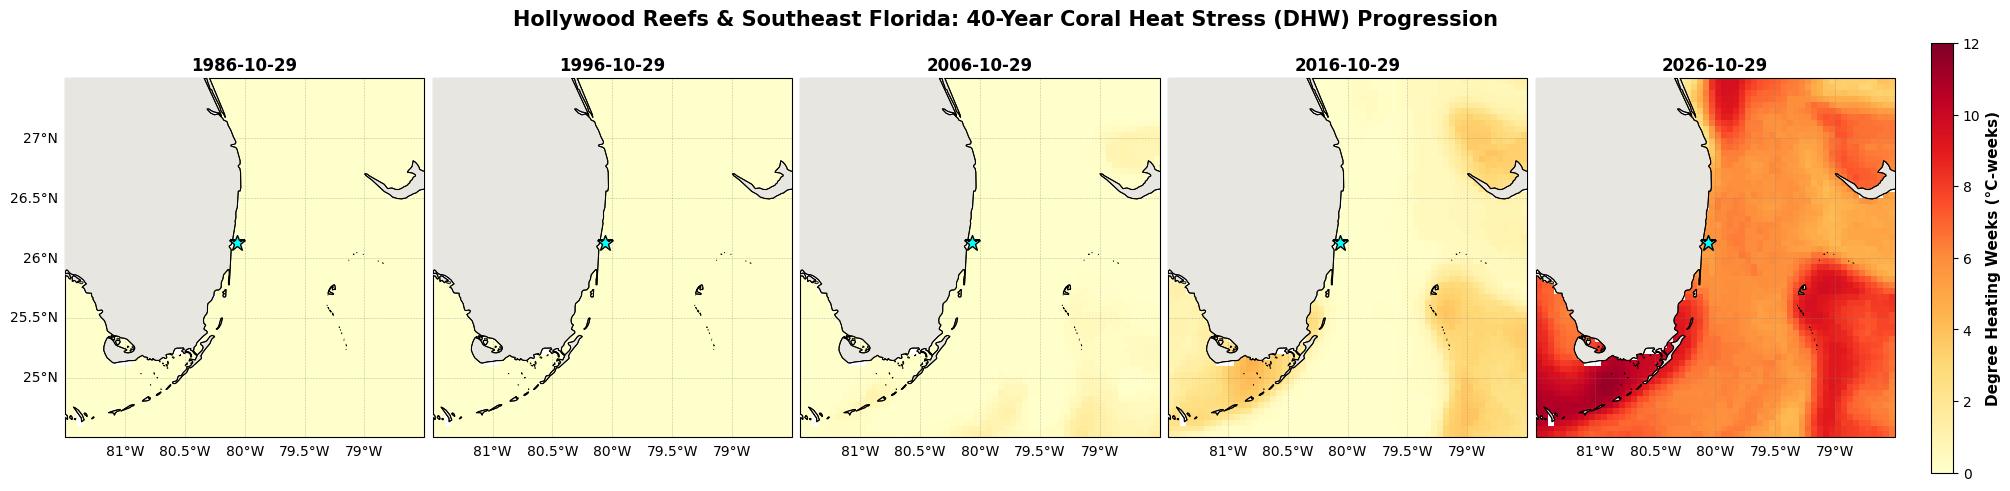

In [6]:

vmin = 0.0
vmax = max(8.0, float(np.ceil(regional_dhw.max())))

fig, axes = plt.subplots(
    1,
    len(target_dates),
    figsize=(20, 4.8),
    subplot_kw={"projection": ccrs.PlateCarree()},
    constrained_layout=True,
)

for i, ax in enumerate(axes):
    slice_2d = regional_dhw.isel(time=i)
    date_label = str(slice_2d.time.values)[:10]

    im = slice_2d.plot(
        ax=ax,
        transform=ccrs.PlateCarree(),
        cmap="YlOrRd",
        vmin=vmin,
        vmax=vmax,
        add_colorbar=False,
    )

    ax.add_feature(cfeature.LAND, facecolor="#e8e6e1", edgecolor="black", linewidth=0.6, zorder=3)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.8, zorder=4)
    ax.set_extent([-81.5, -78.5, 24.5, 27.5], crs=ccrs.PlateCarree())

    # Star Hollywood Reefs (26.125°N, -80.0625°W)
    ax.plot(
        -80.0625,
        26.125,
        marker="*",
        color="cyan",
        markeredgecolor="black",
        markersize=12,
        transform=ccrs.PlateCarree(),
        zorder=5,
        label="Hollywood Reefs",
    )

    gl = ax.gridlines(draw_labels=True, linewidth=0.4, color="gray", alpha=0.5, linestyle="--")
    gl.top_labels = False
    gl.right_labels = False
    if i > 0:
        gl.left_labels = False

    ax.set_title(date_label, fontsize=12, fontweight="bold")

cbar = fig.colorbar(im, ax=axes, orientation="vertical", fraction=0.015, pad=0.02)
cbar.set_label("Degree Heating Weeks (°C-weeks)", fontsize=11, fontweight="bold")
fig.suptitle(
    "Hollywood Reefs & Southeast Florida: 40-Year Coral Heat Stress (DHW) Progression",
    fontsize=15,
    fontweight="bold",
)
plt.show()

In [2]:
# Net cdf caused problems

# !pip install xarray netcdf4 pydap cartopy
# import matplotlib as plt
# import xarray as xr
# import cartopy.crs as ccrs
# import numpy as np

#
# url = "https://coastwatch.pfeg.noaa.gov/erddap/griddap/NOAA_DHW"
# ds = xr.open_dataset(url)

#
# # Tip: Change "-11-15" to "-09-15" if you want to visualize peak summer heat stress
# target_dates = [
#     "1986-11-15T12:00:00",
#     "1996-11-15T12:00:00",
#     "2006-11-15T12:00:00",
#     "2016-11-15T12:00:00",
#     "2026-10-29T12:00:00",
# ]

#
# # IMPORTANT: NOAA_DHW stores latitude North-to-South, so slice MUST be (27.5, 24.5)
# regional_dhw = (
#     ds["CRW_DHW"]
#     .sel(
#         time=target_dates,
#         method="nearest",
#     )
#     .sel(
#         latitude=slice(27.5, 24.5),
#         longitude=slice(-81.5, -78.5),
#     )
#     .load()
# )

#
# vmin = 0.0
# vmax = max(8.0, float(np.ceil(regional_dhw.max())))  # 8 °C-weeks = NOAA severe bleaching threshold

# fig, axes = plt.subplots(
#     1,
#     len(target_dates),
#     figsize=(20, 4.8),
#     subplot_kw={"projection": ccrs.PlateCarree()},
#     constrained_layout=True,
# )

# for i, ax in enumerate(axes):
#     slice_2d = regional_dhw.isel(time=i)
#     date_label = str(slice_2d.time.values)[:10]

#     # Plot DHW field
#     im = slice_2d.plot(
#         ax=ax,
#         transform=ccrs.PlateCarree(),
#         cmap="YlOrRd",
#         vmin=vmin,
#         vmax=vmax,
#         add_colorbar=False,
#     )

#
#     ax.add_feature(cfeature.LAND, facecolor="#e8e6e1", edgecolor="black", linewidth=0.6, zorder=3)
#     ax.add_feature(cfeature.COASTLINE, linewidth=0.8, zorder=4)
#     ax.set_extent([-81.5, -78.5, 24.5, 27.5], crs=ccrs.PlateCarree())

#
#     ax.plot(
#         -80.0625,
#         26.125,
#         marker="*",
#         color="cyan",
#         markeredgecolor="black",
#         markersize=12,
#         transform=ccrs.PlateCarree(),
#         zorder=5,
#         label="Hollywood Reefs",
#     )

#     gl = ax.gridlines(draw_labels=True, linewidth=0.4, color="gray", alpha=0.5, linestyle="--")
#     gl.top_labels = False
#     gl.right_labels = False
#     if i > 0:
#         gl.left_labels = False

#     ax.set_title(date_label, fontsize=12, fontweight="bold")

# cbar = fig.colorbar(im, ax=axes, orientation="vertical", fraction=0.015, pad=0.02)
# cbar.set_label("Degree Heating Weeks (°C-weeks)", fontsize=11, fontweight="bold")

# fig.suptitle(
#     "Hollywood Reefs & Southeast Florida: 40-Year Coral Heat Stress (DHW) Progression",
#     fontsize=15,
#     fontweight="bold",
# )
# plt.show()